# Fraud detection on IEEE-CIS data

Data: Kaggle IEEE-CIS Fraud Detection (Vesta card payments).
Goal: give each payment a risk score so the fraud team only checks the riskiest ones.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict, deque
from scipy import stats

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

DATA_DIR = r"E:\Fraud_Risk_Data\ieee"

## 1. Load data

In [2]:
tx = pd.read_csv(DATA_DIR + "/train_transaction.csv")
identity = pd.read_csv(DATA_DIR + "/train_identity.csv")
print(tx.shape, identity.shape)

df = tx.merge(identity, on="TransactionID", how="left")
print(df.shape)
df.head()

(590540, 394) (144233, 41)


(590540, 434)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,...,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,...,NotFound,166.0,NaN,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [3]:
print("duplicates:", df["TransactionID"].duplicated().sum())
print(df["isFraud"].value_counts())
print("fraud rate:", round(df["isFraud"].mean() * 100, 2), "%")

duplicates: 0
isFraud
0    569877
1     20663
Name: count, dtype: int64
fraud rate: 3.5 %


Only 3.5% fraud. Predicting 'not fraud' for everything gives 96.5% accuracy, so accuracy is not useful here.

## 2. Missing values

In [4]:
missing = df.isnull().mean().sort_values(ascending=False) * 100
print("columns with missing values:", (missing > 0).sum(), "out of", df.shape[1])
missing.head(15)

columns with missing values: 414 out of 434


id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
dtype: float64

In [5]:
c_cols = ["C" + str(i) for i in range(1, 15)]
d_cols = ["D" + str(i) for i in range(1, 16)]
m_cols = ["M" + str(i) for i in range(1, 10)]
v_cols = ["V" + str(i) for i in range(1, 340)]
id_cols = [c for c in df.columns if c.startswith("id_")]

for name, cols in [("C", c_cols), ("D", d_cols), ("M", m_cols), ("V", v_cols), ("id", id_cols)]:
    print(name, len(cols), "columns, average missing %:", round(missing[cols].mean(), 1))

C 14 columns, average missing %: 0.0
D 15 columns, average missing %: 58.2
M 9 columns, average missing %: 49.9
V 339 columns, average missing %: 43.0
id 38 columns, average missing %: 84.8


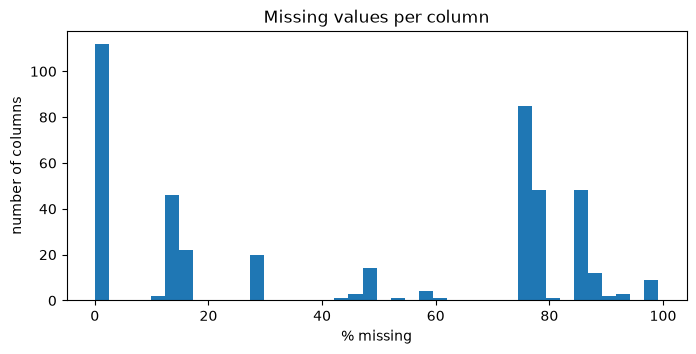

In [6]:
plt.figure(figsize=(8, 3.5))
plt.hist(missing, bins=40)
plt.xlabel("% missing")
plt.ylabel("number of columns")
plt.title("Missing values per column")
plt.show()

Device data is missing for most payments. Checking if that itself is linked to fraud.

In [7]:
df["has_identity"] = df["DeviceType"].notna().astype(int)
df.groupby("has_identity")["isFraud"].agg(["count", "mean"])

,count,mean
has_identity,,
0,449730,0.021017
1,140810,0.079618


Payments with device data have much more fraud (8.0% vs 2.1%), so missing values carry information.

- V columns: 339 anonymised columns, no meaning available, and they go missing together in blocks. Dropping them.
- Other columns: keeping NaN. XGBoost handles it. For the sklearn models I use median imputation.

In [8]:
print("different missing rates among V columns:", df[v_cols].isnull().mean().round(4).nunique())
df = df.drop(columns=v_cols)
df.shape

different missing rates among V columns: 14


(590540, 96)

## 3. Time

TransactionDT is in seconds from a start point, so only day number and hour can be taken from it.

1 182


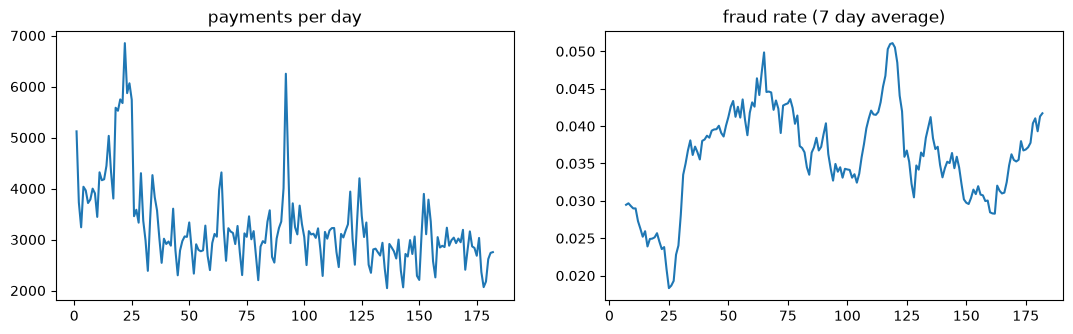

In [9]:
df = df.sort_values("TransactionDT", kind="stable").reset_index(drop=True)
df["day"] = (df["TransactionDT"] // 86400).astype(int)
df["hour"] = (df["TransactionDT"] // 3600) % 24
print(df["day"].min(), df["day"].max())

daily = df.groupby("day")["isFraud"].agg(["count", "mean"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(daily["count"])
ax[0].set_title("payments per day")
ax[1].plot(daily["mean"].rolling(7).mean())
ax[1].set_title("fraud rate (7 day average)")
plt.show()

## 4. Amount distribution and outliers

In [10]:
print(df["TransactionAmt"].describe())
print("skew:", df["TransactionAmt"].skew())
print("skew after log:", np.log1p(df["TransactionAmt"]).skew())

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64
skew: 14.374489573829827
skew after log: 0.4882909971465326


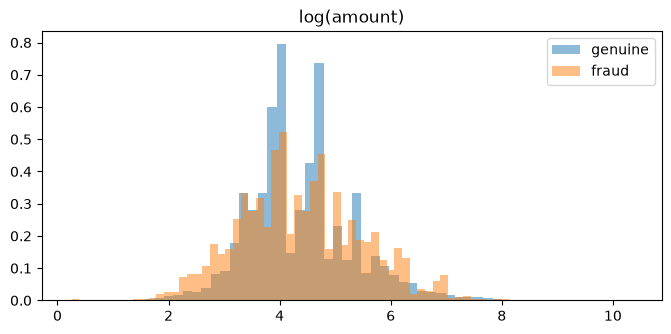

In [11]:
fraud = df[df["isFraud"] == 1]
genuine = df[df["isFraud"] == 0]

plt.figure(figsize=(8, 3.5))
plt.hist(np.log1p(genuine["TransactionAmt"]), bins=60, density=True, alpha=0.5, label="genuine")
plt.hist(np.log1p(fraud["TransactionAmt"]), bins=60, density=True, alpha=0.5, label="fraud")
plt.title("log(amount)")
plt.legend()
plt.show()

Amount is very skewed, so I will add a log version as a feature.

In [12]:
q1 = df["TransactionAmt"].quantile(0.25)
q3 = df["TransactionAmt"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
outlier = df["TransactionAmt"] > upper

print("upper limit:", upper)
print("outliers %:", round(outlier.mean() * 100, 1))
print("fraud rate in outliers:", round(df[outlier]["isFraud"].mean() * 100, 2))
print("fraud rate in the rest:", round(df[~outlier]["isFraud"].mean() * 100, 2))

upper limit: 247.51850000000002
outliers %: 11.3
fraud rate in outliers: 5.07


fraud rate in the rest: 3.3


Keeping the outliers. They are real payments, and they have more fraud. Tree models are not affected by them.

## 5. Statistical tests

First a normality check on log amount. It is not normal, so I use Mann-Whitney instead of a t-test.

In [13]:
sample = np.log1p(df["TransactionAmt"].sample(5000, random_state=42))
print("normality p-value:", stats.normaltest(sample).pvalue)

for col in ["TransactionAmt", "D1"]:
    a = fraud[col].dropna()
    b = genuine[col].dropna()
    p = stats.mannwhitneyu(a, b).pvalue
    print(col, "| median fraud:", a.median(), "| median genuine:", b.median(), "| p-value:", round(p, 4))

normality p-value: 2.959979708996463e-45
TransactionAmt | median fraud: 75.0 | median genuine: 68.5 | p-value: 0.2259


D1 | median fraud: 0.0 | median genuine: 4.0 | p-value: 0.0


- Amount: p = 0.23, so no real difference between fraud and genuine.
- D1 (days since the account started): fraud comes from newer accounts.

Chi-square for the categorical columns. With this much data p-values are almost always small, so I also check Cramer's V for strength.

In [14]:
def cramers_v(col):
    table = pd.crosstab(df[col].fillna("missing"), df["isFraud"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return round(chi2), p, round(v, 3)

for col in ["ProductCD", "card6", "has_identity"]:
    print(col, cramers_v(col))

ProductCD (16742, np.float64(0.0), np.float64(0.168))
card6 (5966, np.float64(0.0), np.float64(0.101))
has_identity (10904, np.float64(0.0), np.float64(0.136))


In [15]:
df.groupby("ProductCD")["isFraud"].agg(["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
ProductCD,,
C,68519,0.116873
S,11628,0.058996
H,33024,0.047662
R,37699,0.037826
W,439670,0.020399


Product C has the highest fraud rate. No single column separates fraud on its own, so a model is needed.

## 6. Feature engineering

### 6.1 Customer key
There is no customer ID in the data. I used the key shared by the winning Kaggle team: card1 + addr1 + (day - D1).
day - D1 is the day the account started, so it stays the same across payments of one customer.

In [16]:
# map(str) keeps missing values as the text "nan". astype(str) in pandas 3 keeps them as NaN and the key is lost.
df["uid"] = df["card1"].map(str) + "_" + df["addr1"].map(str) + "_" + (df["day"] - df["D1"]).map(str)
print("customers:", df["uid"].nunique())
print("payments with no key:", df["uid"].isna().sum())

df["card_key"] = df["card1"].map(str)
for col in ["card2", "card3", "card4", "card5", "card6"]:
    df["card_key"] = df["card_key"] + "_" + df[col].map(str)

customers: 217850
payments with no key: 0


In [17]:
per_customer = df.groupby("uid")["isFraud"].agg(["count", "mean"])
print(per_customer["count"].describe())

many = per_customer[per_customer["count"] >= 2]
has_fraud = many[many["mean"] > 0]
print("customers with 2+ payments and some fraud:", len(has_fraud))
print("of those, all payments are fraud:", round((has_fraud["mean"] == 1).mean() * 100, 1), "%")

count    217850.000000
mean          2.710764
std           5.457783
min           1.000000
25%           1.000000
50%           1.000000
75%           3.000000
max        1414.000000
Name: count, dtype: float64
customers with 2+ payments and some fraud: 5102
of those, all payments are fraud: 39.0 %


Vesta labels later payments of a caught account as fraud too, so I will check later how much the model depends on this.

### 6.2 Simple features

In [18]:
df["log_amt"] = np.log1p(df["TransactionAmt"])
df["email_match"] = np.where(df["R_emaildomain"].isna(), np.nan, (df["P_emaildomain"] == df["R_emaildomain"]).astype(float))

cat_cols = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain", "DeviceType", "DeviceInfo"] + m_cols
for col in cat_cols:
    df[col + "_code"] = df[col].astype("category").cat.codes.replace(-1, np.nan)

### 6.3 Time window features
For each payment I go through the data in time order and look only at earlier payments of that customer and card.
The features are calculated first and the payment is added to the history after, so nothing from the future is used.

In [19]:
H1 = 3600
H24 = 86400
D7 = 7 * 86400

def new_customer():
    return {"recent": deque(), "n": 0, "total": 0.0, "last_t": None, "devices": set(), "emails": set()}

def new_card():
    return {"recent": deque(), "n": 0, "total": 0.0, "addrs": set()}

customers = defaultdict(new_customer)
cards = defaultdict(new_card)
rows = []

use = ["TransactionDT", "TransactionAmt", "uid", "card_key", "ProductCD", "DeviceInfo", "P_emaildomain", "addr1"]
for r in df[use].to_dict("records"):
    t = float(r["TransactionDT"])
    amt = float(r["TransactionAmt"])
    device, email, addr = r["DeviceInfo"], r["P_emaildomain"], r["addr1"]
    u = customers[r["uid"]]
    c = cards[r["card_key"]]

    # remove anything older than 7 days
    while u["recent"] and u["recent"][0][0] < t - D7:
        u["recent"].popleft()
    while c["recent"] and c["recent"][0][0] < t - D7:
        c["recent"].popleft()

    # customer history
    cnt_1h, cnt_24h, cnt_7d, amt_24h = 0, 0, 0, 0.0
    products = set()
    for old_t, old_amt, product in reversed(u["recent"]):
        gap = t - old_t
        cnt_7d += 1
        products.add(product)
        if gap <= H24:
            cnt_24h += 1
            amt_24h += old_amt
            if gap <= H1:
                cnt_1h += 1

    # card history
    card_1h, card_24h = 0, 0
    card_uids = set()
    for old_t, old_amt, old_uid in reversed(c["recent"]):
        gap = t - old_t
        if gap > H24:
            break
        card_24h += 1
        card_uids.add(old_uid)
        if gap <= H1:
            card_1h += 1

    rows.append({
        "uid_cnt_1h": cnt_1h,
        "uid_cnt_24h": cnt_24h,
        "uid_cnt_7d": cnt_7d,
        "uid_amt_24h": amt_24h,
        "uid_hist_cnt": u["n"],
        "uid_amt_mean": u["total"] / u["n"] if u["n"] else np.nan,
        "uid_amt_ratio": amt / (u["total"] / u["n"]) if u["n"] >= 2 and u["total"] > 0 else np.nan,
        "uid_secs_since_last": t - u["last_t"] if u["last_t"] is not None else np.nan,
        "uid_new_device": int(isinstance(device, str) and u["n"] > 0 and device not in u["devices"]),
        "uid_new_email": int(isinstance(email, str) and u["n"] > 0 and email not in u["emails"]),
        "uid_distinct_products_7d": len(products),
        "card_cnt_1h": card_1h,
        "card_cnt_24h": card_24h,
        "card_distinct_uid_24h": len(card_uids),
        "card_amt_ratio": amt / (c["total"] / c["n"]) if c["n"] >= 2 and c["total"] > 0 else np.nan,
        "card_new_addr": int(addr == addr and c["n"] > 0 and addr not in c["addrs"]),
    })

    # now add this payment to the history
    u["recent"].append((t, amt, r["ProductCD"]))
    u["n"] += 1
    u["total"] += amt
    u["last_t"] = t
    if isinstance(device, str):
        u["devices"].add(device)
    if isinstance(email, str):
        u["emails"].add(email)
    c["recent"].append((t, amt, r["uid"]))
    c["n"] += 1
    c["total"] += amt
    if addr == addr:
        c["addrs"].add(addr)

window = pd.DataFrame(rows)
window_cols = list(window.columns)
df = pd.concat([df, window], axis=1)
print(df.shape)

(590540, 134)


Check: the first payment of every customer should have no history.

In [20]:
first = df.groupby("uid").head(1)
print((first["uid_hist_cnt"] == 0).mean())

1.0


In [21]:
df.groupby("isFraud")[["uid_cnt_24h", "uid_cnt_7d", "uid_amt_ratio", "uid_secs_since_last"]].mean()

,uid_cnt_24h,uid_cnt_7d,uid_amt_ratio,uid_secs_since_last
isFraud,,,,
0,1.956291,2.837467,1.122759,891806.435732
1,2.336882,3.554711,1.139046,286908.020042


In [22]:
base_cols = ["log_amt", "hour", "email_match", "has_identity"]
num_cols = ["TransactionAmt", "card1", "card2", "card3", "card5", "addr1", "addr2", "dist1"] + c_cols + ["D1", "D2", "D3", "D4", "D10", "D15"]
code_cols = [c + "_code" for c in cat_cols]

features = base_cols + num_cols + code_cols + window_cols
print(len(features), "features")

64 features


## 7. Train / validation / test split

Split by time, not random, because in real use the model only sees the past.
Train is days 1-120, validation is 121-150 (to choose the model and thresholds), test is 151-182 (used once at the end).

In [23]:
train = df[df["day"] < 121]
val = df[(df["day"] >= 121) & (df["day"] < 151)]
test = df[df["day"] >= 151]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(name, len(part), "fraud %:", round(part["isFraud"].mean() * 100, 2))

X_train, y_train = train[features], train["isFraud"].values
X_val, y_val = val[features], val["isFraud"].values
X_test, y_test = test[features], test["isFraud"].values

train 414542 fraud %: 3.52
val 83571 fraud %: 3.41
test 92427 fraud %: 3.48


## 8. Metric

The fraud team can only check a small number of payments. So I sort payments by score, take the top 1%,
and check precision (how many flagged are fraud) and recall (how much of all fraud is found).
I also look at PR-AUC, which is better than ROC-AUC when the positive class is rare.

In [24]:
def top_percent(y, score, pct):
    k = int(round(len(score) * pct))
    top = np.argsort(-score)[:k]
    precision = y[top].mean()
    recall = y[top].sum() / y.sum()
    return precision, recall

## 9. Baseline: simple rules

Four hand-written velocity rules. I set the thresholds by hand. A payment is flagged if any rule fires.

In [25]:
def apply_rules(d):
    rule1 = (d["uid_cnt_1h"] >= 3) & (d["uid_amt_ratio"] >= 3)
    rule2 = (d["uid_new_device"] == 1) & (d["uid_amt_ratio"] >= 3)
    rule3 = (d["uid_new_email"] == 1) & (d["TransactionAmt"] >= 500)
    rule4 = (d["email_match"] == 0) & (d["TransactionAmt"] >= 300)
    return rule1 | rule2 | rule3 | rule4

flag = apply_rules(val)
print("flagged:", flag.sum())
print("precision:", round(val[flag]["isFraud"].mean(), 3))
print("recall:", round(val[flag]["isFraud"].sum() / val["isFraud"].sum(), 3))

flagged: 530
precision: 0.104
recall: 0.019


## 10. Models

Same features for all models. For the imbalance I use class weights. The best model is picked on validation PR-AUC.

In [26]:
spw = (1 - y_train.mean()) / y_train.mean()
print("scale_pos_weight:", round(spw, 1))

def make_xgb():
    return XGBClassifier(n_estimators=600, max_depth=7, learning_rate=0.05, subsample=0.8, colsample_bytree=0.6,
                         min_child_weight=5, scale_pos_weight=spw, eval_metric="aucpr", tree_method="hist",
                         random_state=42, n_jobs=-1)

models = {
    "logistic_regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000)),
    "decision_tree": make_pipeline(SimpleImputer(strategy="median"),
                                   DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=42)),
    "random_forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20,
                                                          class_weight="balanced_subsample", n_jobs=-1, random_state=42)),
    "hist_gradient_boosting": HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=63,
                                                             class_weight="balanced", random_state=42),
    "xgboost": make_xgb(),
}

scale_pos_weight: 27.4


In [27]:
results = []
val_scores = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    score = model.predict_proba(X_val)[:, 1]
    val_scores[name] = score
    p1, r1 = top_percent(y_val, score, 0.01)
    p5, r5 = top_percent(y_val, score, 0.05)
    results.append([name, roc_auc_score(y_val, score), average_precision_score(y_val, score), p1, r1, p5, r5])
    print(name, "done")

results = pd.DataFrame(results, columns=["model", "roc_auc", "pr_auc", "precision_1pct", "recall_1pct", "precision_5pct", "recall_5pct"])
results = results.sort_values("pr_auc", ascending=False).reset_index(drop=True)
results.round(4)

logistic_regression done


decision_tree done


random_forest done


hist_gradient_boosting done


xgboost done


,model,roc_auc,pr_auc,precision_1pct,recall_1pct,precision_5pct,recall_5pct
0,xgboost,0.9170,0.5351,0.8684,0.2547,0.4075,0.5975
1,hist_gradient_boosting,0.9160,0.5141,0.8517,0.2498,0.3898,0.5716
2,random_forest,0.8967,0.4758,0.8301,0.2435,0.3585,0.5256
3,decision_tree,0.8185,0.2875,0.5981,0.1754,0.2804,0.4112
4,logistic_regression,0.8300,0.2640,0.4450,0.1305,0.2477,0.3632


Area under each curve, per model (validation). Higher is better.

In [28]:
for name, score in val_scores.items():
    print(f"{name:24s} ROC-AUC: {roc_auc_score(y_val, score):.3f}   PR-AUC: {average_precision_score(y_val, score):.3f}")

logistic_regression      ROC-AUC: 0.830   PR-AUC: 0.264
decision_tree            ROC-AUC: 0.819   PR-AUC: 0.288
random_forest            ROC-AUC: 0.897   PR-AUC: 0.476
hist_gradient_boosting   ROC-AUC: 0.916   PR-AUC: 0.514
xgboost                  ROC-AUC: 0.917   PR-AUC: 0.535


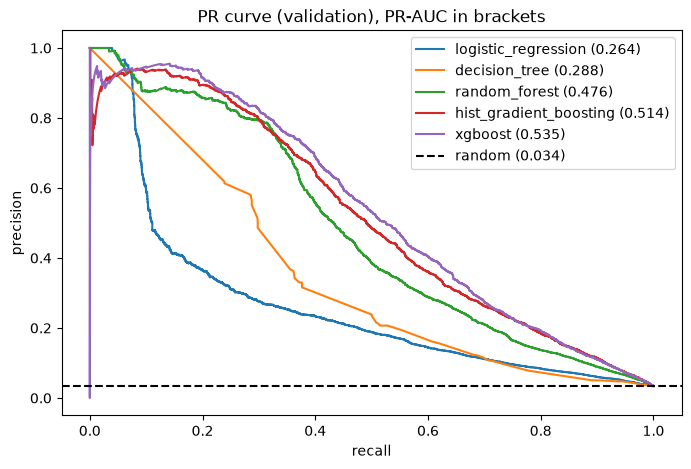

In [29]:
plt.figure(figsize=(8, 5))
for name, score in val_scores.items():
    prec, rec, _ = precision_recall_curve(y_val, score)
    plt.plot(rec, prec, label=f"{name} ({average_precision_score(y_val, score):.3f})")
plt.axhline(y_val.mean(), color="k", ls="--", label=f"random ({y_val.mean():.3f})")
plt.title("PR curve (validation), PR-AUC in brackets")
plt.xlabel("recall")
plt.ylabel("precision")
plt.legend()
plt.show()

The higher the line, the better: at the same recall, more of the alerts are real fraud. With only 3.5% fraud,
ROC-AUC looks good for every model, so I use PR-AUC to choose.

In [30]:
best_name = results.loc[0, "model"]
best_model = models[best_name]
print("best model:", best_name)

best model: xgboost


## 11. Thresholds

Taken from validation scores and then used as they are on test. Block the top 0.5%, send up to the top 2% for review / OTP.

In [31]:
thr_block = np.quantile(val_scores[best_name], 0.995)
thr_review = np.quantile(val_scores[best_name], 0.98)
print(thr_block, thr_review)

0.99230254 0.8426805


## 12. Final test

In [32]:
test_score = best_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, test_score), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_score), 4))

p1, r1 = top_percent(y_test, test_score, 0.01)
p5, r5 = top_percent(y_test, test_score, 0.05)

ROC-AUC: 0.8977
PR-AUC: 0.4948


### How many payments can the team check?
Precision and recall depend on how many payments are checked. Checking more finds more fraud (recall goes up),
but more of the alerts are genuine customers (precision goes down). The bank picks this budget.

In [33]:
total_fraud = y_test.sum()
rows = []
for pct in [0.01, 0.02, 0.05, 0.10]:
    k = int(round(len(test_score) * pct))
    precision, recall = top_percent(y_test, test_score, pct)
    rows.append([str(int(pct * 100)) + "%", k, int(round(precision * k)), round(precision * 100, 1), round(recall * 100, 1)])

budget = pd.DataFrame(rows, columns=["checked", "payments flagged", "real fraud", "precision %", "recall %"])
print("fraud in the test month:", total_fraud)
budget

fraud in the test month: 3213


,checked,payments flagged,real fraud,precision %,recall %
0,1%,924,800,86.6,24.9
1,2%,1849,1236,66.8,38.5
2,5%,4621,1744,37.7,54.3
3,10%,9243,2146,23.2,66.8


- At 1% the alerts are very clean, but most fraud is missed.
- At 5% about half of all fraud is found, but most alerts are genuine customers.
- So hard blocks use only the very top, and the next band gets an OTP instead (next cell).

In [34]:
block = test_score >= thr_block
review = (test_score >= thr_review) & ~block
both = block | review
total_fraud = y_test.sum()

print("block : share", round(block.mean(), 4), "precision", round(y_test[block].mean(), 4), "fraud caught", round(y_test[block].sum() / total_fraud, 4))
print("review: share", round(review.mean(), 4), "precision", round(y_test[review].mean(), 4), "fraud caught", round(y_test[review].sum() / total_fraud, 4))
print("both  : share", round(both.mean(), 4), "precision", round(y_test[both].mean(), 4), "fraud caught", round(y_test[both].sum() / total_fraud, 4))

block : share 0.0051 precision 0.9066 fraud caught 0.1329
review: share 0.0162 precision 0.5639 fraud caught 0.2624
both  : share 0.0213 precision 0.646 fraud caught 0.3953


Rules on the same test month:

In [35]:
flag = apply_rules(test)
print("flagged:", flag.sum())
print("fraud found:", test[flag]["isFraud"].sum(), "out of", test["isFraud"].sum())
rule_precision = test[flag]["isFraud"].mean()
rule_recall = test[flag]["isFraud"].sum() / test["isFraud"].sum()
print("precision:", round(rule_precision, 4), "recall:", round(rule_recall, 4))

flagged: 566
fraud found: 59 out of 3213
precision: 0.1042 recall: 0.0184


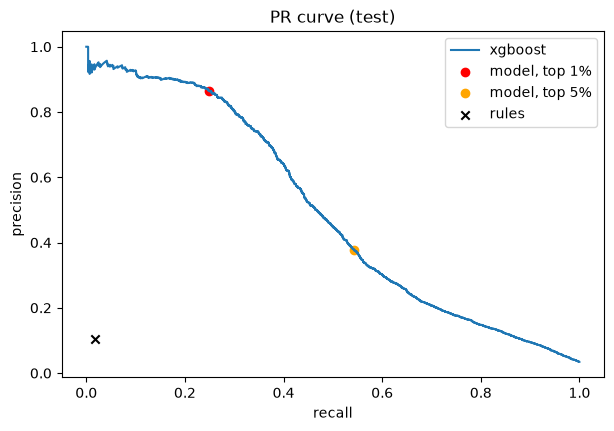

In [36]:
prec, rec, _ = precision_recall_curve(y_test, test_score)
plt.figure(figsize=(7, 4.5))
plt.plot(rec, prec, label=best_name)
plt.scatter([r1], [p1], color="red", label="model, top 1%")
plt.scatter([r5], [p5], color="orange", label="model, top 5%")
plt.scatter([rule_recall], [rule_precision], color="black", marker="x", label="rules")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("PR curve (test)")
plt.legend()
plt.show()

## 13. Feature importance

share of window features: 10.7 %
C8                0.111122
C4                0.085123
C5                0.070192
C14               0.055032
card6_code        0.035087
C1                0.033737
D3                0.031654
M4_code           0.027544
ProductCD_code    0.026176
C10               0.024593
dtype: float32


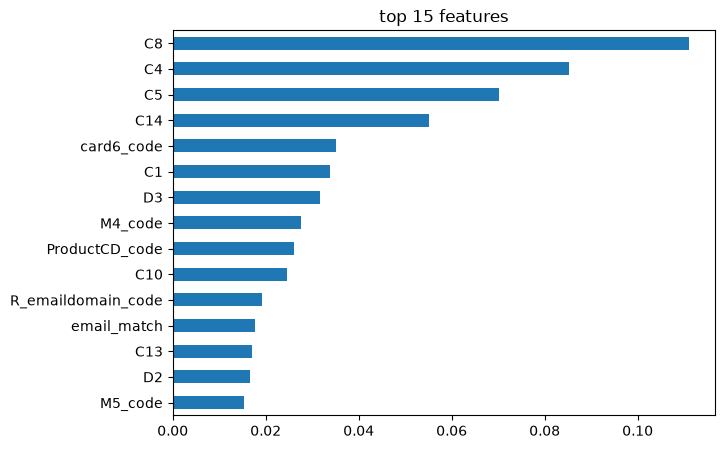

In [37]:
importance = pd.Series(best_model.feature_importances_, index=features).sort_values(ascending=False)
print("share of window features:", round(importance[window_cols].sum() / importance.sum() * 100, 1), "%")
print(importance.head(10))

importance.head(15)[::-1].plot(kind="barh", figsize=(7, 5), title="top 15 features")
plt.show()

## 14. Extra checks

How much of the caught fraud comes from accounts already known as fraud before the test month? And how does it do on new customers?

In [38]:
top = np.argsort(-test_score)[:int(round(len(y_test) * 0.01))]
top1 = np.zeros(len(y_test), dtype=bool)
top1[top] = True

before = pd.concat([train, val])
seen_before = test["uid"].isin(before["uid"]).values
known_bad = test["uid"].isin(before[before["isFraud"] == 1]["uid"]).values

caught = top1 & (y_test == 1)
print("caught fraud from known bad accounts:", round((caught & known_bad).sum() / caught.sum() * 100, 1), "%")

new = ~seen_before
print("new customers:", new.sum())
print("precision on new customers:", round(y_test[top1 & new].mean() * 100, 1), "%")
print("recall on new customers:", round((top1 & new & (y_test == 1)).sum() / (new & (y_test == 1)).sum() * 100, 1), "%")

caught fraud from known bad accounts: 14.4 %
new customers: 50726
precision on new customers: 84.9 %
recall on new customers: 28.2 %


## 15. Save the model

The API needs four things: the model, the feature list, the two thresholds and the category codes.
It also needs the payment history up to day 150 to calculate the window features, so I save that too.

In [39]:
import os
import joblib

category_maps = {}
for col in cat_cols:
    categories = df[col].astype("category").cat.categories
    category_maps[col] = {value: i for i, value in enumerate(categories)}

bundle = {
    "model": best_model,
    "model_name": best_name,
    "features": features,
    "thr_block": float(thr_block),
    "thr_review": float(thr_review),
    "category_maps": category_maps,
}

os.makedirs("../models", exist_ok=True)
joblib.dump(bundle, "../models/fraud_model.pkl")
print("model file size (MB):", round(os.path.getsize("../models/fraud_model.pkl") / 1e6, 1))

model file size (MB): 3.9


In [40]:
raw_cols = (["TransactionID", "TransactionDT", "TransactionAmt", "ProductCD", "card1", "card2", "card3", "card4", "card5", "card6",
             "addr1", "addr2", "dist1", "P_emaildomain", "R_emaildomain", "DeviceType", "DeviceInfo"]
            + c_cols + ["D1", "D2", "D3", "D4", "D10", "D15"] + m_cols)

history = df[df["day"] < 151][raw_cols]
history.to_parquet(r"E:\Fraud_Risk_Data\history_until_day150.parquet", index=False)

# first 2000 test payments with the score from this notebook, to compare with the API later
sample = test.head(2000)[raw_cols + ["isFraud"]].copy()
sample["notebook_score"] = test_score[:2000]
sample.to_parquet(r"E:\Fraud_Risk_Data\test_sample_2000.parquet", index=False)
print(history.shape, sample.shape)

(498113, 46) (2000, 48)


## 16. Conclusion

- XGBoost was the best on validation (PR-AUC 0.535), then HistGradientBoosting (0.514), random forest (0.476), decision tree (0.288), logistic regression (0.264).
- On the test month, the riskiest 1% (924 payments) were 87% fraud and held 25% of all fraud (800 of 3,213).
- The hand-written rules flagged 566 payments, 10% were fraud, and they found 1.8% of all fraud.
- Blocking the top 0.5% was 91% correct.
- Only 14% of the caught fraud was from accounts already known as fraud. On new customers precision was 85%.
- Amount alone does not separate fraud; account age, product type and device data do.

The saved model is served with FastAPI in the next notebook (02_fraud_fastapi_serving.ipynb).

Next: tune the rule thresholds on training data and add SHAP.